In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.sparse import hstack

In [2]:
df = pd.read_csv("CFO_001_customer_churn_clean.csv")

In [3]:
df.head(10)

,customer_id,age,tenure_months,monthly_charges,support_calls,monthly_data_gb,contract_type,payment_method,internet_service,paperless_billing,churn
0,C00001,23,59,51.67,0,148.0,Two year,Electronic check,DSL,Yes,0
1,C00002,62,54,88.34,1,60.9,Month-to-month,Bank transfer,Fiber,Yes,1
2,C00003,55,41,68.76,1,97.6,Month-to-month,Bank transfer,No internet,Yes,1
3,C00004,43,64,61.78,0,76.8,Month-to-month,Bank transfer,DSL,No,0
4,C00005,42,10,65.66,2,187.3,Month-to-month,Credit card,DSL,Yes,0
5,C00006,66,67,72.91,0,153.3,Month-to-month,Bank transfer,No internet,No,0
6,C00007,22,62,81.57,0,36.3,Month-to-month,Credit card,DSL,Yes,0
7,C00008,57,37,46.01,1,62.5,One year,Electronic check,DSL,Yes,0
8,C00009,29,53,45.09,2,115.0,Two year,Electronic check,No internet,No,0
9,C00010,23,38,92.30,2,102.0,Month-to-month,Mailed check,Fiber,No,1


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        1000 non-null   str    
 1   age                1000 non-null   int64  
 2   tenure_months      1000 non-null   int64  
 3   monthly_charges    1000 non-null   float64
 4   support_calls      1000 non-null   int64  
 5   monthly_data_gb    1000 non-null   float64
 6   contract_type      1000 non-null   str    
 7   payment_method     1000 non-null   str    
 8   internet_service   1000 non-null   str    
 9   paperless_billing  1000 non-null   str    
 10  churn              1000 non-null   int64  
dtypes: float64(2), int64(4), str(5)
memory usage: 86.1 KB


In [5]:
X = df.drop(["churn", "customer_id"], axis=1)

In [6]:
numerical_col = X.select_dtypes(include="number").columns
categorical_col = X.select_dtypes(exclude="number").columns

In [7]:
scaler = StandardScaler()
encoder = OneHotEncoder(handle_unknown="ignore")

In [8]:
X_scaled = scaler.fit_transform(X[numerical_col])
X_encoded = encoder.fit_transform(X[categorical_col])

In [9]:
X_processed = hstack([
    X_scaled,
    X_encoded
])

In [10]:
print(X_processed.shape)

(1000, 17)


In [11]:
model = KMeans(
    n_clusters=3,
    init="k-means++",
    n_init=10,
    random_state=42
)

In [12]:
labels = model.fit_predict(X_processed)

In [13]:
df["clusters"] = labels

In [14]:
print(df[["clusters", "customer_id"]].head(10))

   clusters customer_id
0         2      C00001
1         0      C00002
2         0      C00003
3         2      C00004
4         1      C00005
5         0      C00006
6         2      C00007
7         0      C00008
8         2      C00009
9         2      C00010


In [15]:
wcss = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )
    model.fit_predict(X_processed)
    wcss.append(model.inertia_)

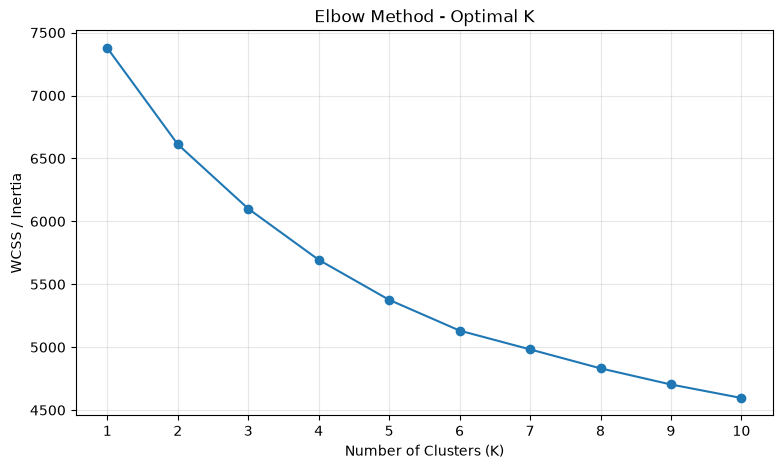

In [16]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker="o",
)

plt.title("Elbow Method - Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS / Inertia")
plt.xticks(range(1, 11))
plt.grid(alpha=0.3)
plt.show()

In [17]:
silhouette_scores = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )
    labels = model.fit_predict(X_processed)
    score = silhouette_score(
        X_processed,
        labels
    )
    silhouette_scores.append(score)

    print(f"for K = {k}, scores: {score:.4f}")
    

for K = 2, scores: 0.1015
for K = 3, scores: 0.0987
for K = 4, scores: 0.0945
for K = 5, scores: 0.0951
for K = 6, scores: 0.0946
for K = 7, scores: 0.0879
for K = 8, scores: 0.0878
for K = 9, scores: 0.0879
for K = 10, scores: 0.0848
